# Yüz Noktası Tespiti (Facial Keypoints Detection)
Gri tonlamalı yüz fotoğraflarında 15 yüz noktasının konumunu bulmamız isteniyor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import train_test_split

In [2]:
train = pd.read_csv('training.csv')
test = pd.read_csv('test.csv')
lookup = pd.read_csv('IdLookupTable.csv')
sample = pd.read_csv('SampleSubmission.csv')

def goruntu_oku(sutun):
    return np.stack(sutun.apply(lambda s: np.array(s.split(), dtype=np.float32))) / 255.

X = goruntu_oku(train.Image)
X_test = goruntu_oku(test.Image)
sutunlar = [c for c in train.columns if c != 'Image']
Y = train[sutunlar].values.astype(float)      

print('train görüntü:', X.shape, '| test görüntü:', X_test.shape, '| koordinat:', Y.shape)
train.head(3)

train görüntü: (7049, 9216) | test görüntü: (1783, 9216) | koordinat: (7049, 30)


,left_eye_center_x,left_eye_center_y,right_eye_center_x,right_eye_center_y,left_eye_inner_corner_x,left_eye_inner_corner_y,left_eye_outer_corner_x,left_eye_outer_corner_y,right_eye_inner_corner_x,right_eye_inner_corner_y,...,nose_tip_y,mouth_left_corner_x,mouth_left_corner_y,mouth_right_corner_x,mouth_right_corner_y,mouth_center_top_lip_x,mouth_center_top_lip_y,mouth_center_bottom_lip_x,mouth_center_bottom_lip_y,Image
0,66.033564,39.002274,30.227008,36.421678,59.582075,39.647423,73.130346,39.969997,36.356571,37.389402,...,57.066803,61.195308,79.970165,28.614496,77.388992,43.312602,72.935459,43.130707,84.485774,238 236 237 238 240 240 239 241 241 243 240 23...
1,64.332936,34.970077,29.949277,33.448715,58.856170,35.274349,70.722723,36.187166,36.034723,34.361532,...,55.660936,56.421447,76.352000,35.122383,76.047660,46.684596,70.266553,45.467915,85.480170,219 215 204 196 204 211 212 200 180 168 178 19...
2,65.057053,34.909642,30.903789,34.909642,59.412000,36.320968,70.984421,36.320968,37.678105,36.320968,...,53.538947,60.822947,73.014316,33.726316,72.732000,47.274947,70.191789,47.274947,78.659368,144 142 159 180 188 188 184 180 167 132 84 59 ...


In [3]:
nokta_adlari = [c[:-2] for c in sutunlar[::2]]    
mevcut = pd.Series((~np.isnan(Y[:, ::2])).sum(0), index=nokta_adlari)
print(mevcut.sort_values())
print()
print('15 noktanın hepsi dolu olan görüntü sayısı:', (~np.isnan(Y).any(axis=1)).sum(), '/', len(Y))

left_eyebrow_outer_end     2225
right_eyebrow_outer_end    2236
left_eye_outer_corner      2267
right_eye_inner_corner     2268
right_eye_outer_corner     2268
mouth_left_corner          2269
left_eyebrow_inner_end     2270
right_eyebrow_inner_end    2270
mouth_right_corner         2270
left_eye_inner_corner      2271
mouth_center_top_lip       2275
mouth_center_bottom_lip    7016
right_eye_center           7036
left_eye_center            7039
nose_tip                   7049
dtype: int64

15 noktanın hepsi dolu olan görüntü sayısı: 2140 / 7049


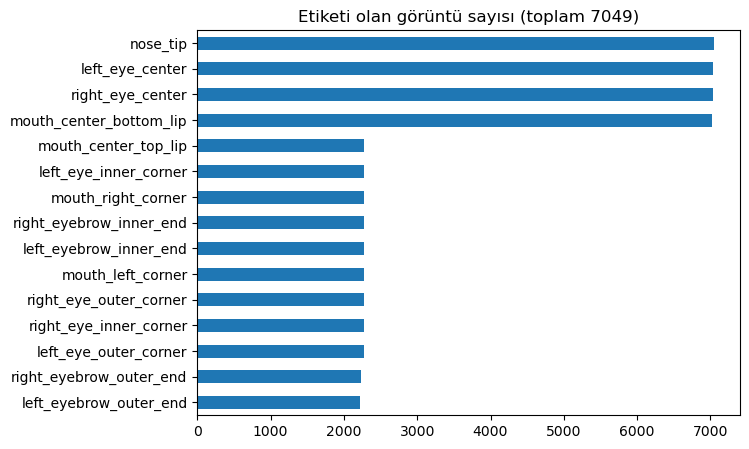

In [4]:
mevcut.sort_values().plot(kind='barh', figsize=(7, 5))
plt.title('Etiketi olan görüntü sayısı (toplam 7049)')
plt.show()

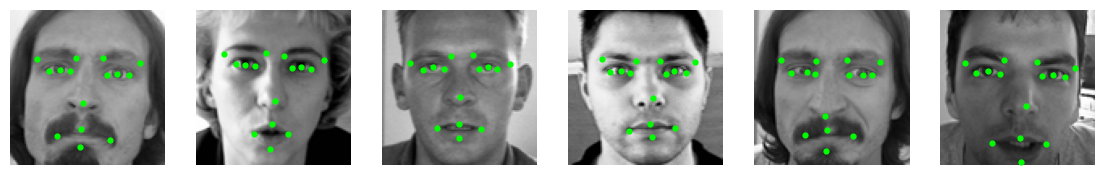

In [5]:
tam = np.where(~np.isnan(Y).any(axis=1))[0][:6]
fig, eksenler = plt.subplots(1, 6, figsize=(14, 3))
for ax, i in zip(eksenler, tam):
    ax.imshow(X[i].reshape(96, 96), cmap='gray')
    ax.scatter(Y[i, ::2], Y[i, 1::2], c='lime', s=12)
    ax.axis('off')

In [6]:
def rmse(y, tahmin):
    var = ~np.isnan(y)                      # sadece etiketi olan noktalar
    return np.sqrt(np.mean((y[var] - tahmin[var]) ** 2))

egitim_idx, dogrulama_idx = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42)
Y_e, Y_d = Y[egitim_idx], Y[dogrulama_idx]
print('eğitim:', len(egitim_idx), '| doğrulama:', len(dogrulama_idx))

sonuclar = {}

eğitim: 5639 | doğrulama: 1410


In [7]:
def hog_cikar(goruntu):
    return hog(goruntu.reshape(96, 96), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))

H = np.stack([hog_cikar(g) for g in X])
H_test = np.stack([hog_cikar(g) for g in X_test])
print('HOG özellikleri:', H.shape, '| test:', H_test.shape)

HOG özellikleri: (7049, 4356) | test: (1783, 4356)


In [8]:
def egit(model_fn, Z, Y):
    modeller, ortalamalar = [], []
    for k in range(15):                                    
        var = ~np.isnan(Y[:, 2 * k])                       
        ort = Y[var, 2 * k:2 * k + 2].mean(0)              
        modeller.append(model_fn().fit(Z[var], Y[var, 2 * k:2 * k + 2] - ort))  
        ortalamalar.append(ort)
    return modeller, ortalamalar

def tahmin_et(modeller, ortalamalar, Z):
    tahmin = np.zeros((len(Z), 30))
    for k in range(15):
        tahmin[:, 2 * k:2 * k + 2] = modeller[k].predict(Z) + ortalamalar[k]
    return tahmin

In [9]:
ortalama_yuz = np.nanmean(Y_e, axis=0)
sonuclar['Ortalama yüz (referans)'] = rmse(Y_d, np.tile(ortalama_yuz, (len(Y_d), 1)))
print(round(sonuclar['Ortalama yüz (referans)'], 4))

3.862


In [10]:
pca_piksel = PCA(n_components=150, random_state=0).fit(X[egitim_idx])
Zp_e, Zp_d = pca_piksel.transform(X[egitim_idx]), pca_piksel.transform(X[dogrulama_idx])

m, o = egit(lambda: Ridge(alpha=100), Zp_e, Y_e)
sonuclar['Ham piksel (PCA) + Ridge'] = rmse(Y_d, tahmin_et(m, o, Zp_d))
print(round(sonuclar['Ham piksel (PCA) + Ridge'], 4))

2.9992


In [11]:
m, o = egit(lambda: Ridge(alpha=100), H[egitim_idx], Y_e)
sonuclar['HOG + Ridge'] = rmse(Y_d, tahmin_et(m, o, H[dogrulama_idx]))
print(round(sonuclar['HOG + Ridge'], 4))

2.382


In [12]:
gamma = 0.5 / (H.shape[1] * H[egitim_idx].var())
m, o = egit(lambda: KernelRidge(alpha=0.1, kernel='rbf', gamma=gamma), H[egitim_idx], Y_e)
sonuclar['HOG + Kernel Ridge'] = rmse(Y_d, tahmin_et(m, o, H[dogrulama_idx]))
print(round(sonuclar['HOG + Kernel Ridge'], 4))

2.1944


In [13]:
pca_hog = PCA(n_components=150, random_state=0).fit(H[egitim_idx])
Z_e = pca_hog.transform(H[egitim_idx]).astype(np.float32)
Z_d = pca_hog.transform(H[dogrulama_idx]).astype(np.float32)

gamma_z = 0.5 / (Z_e.shape[1] * Z_e.var())
m, o = egit(lambda: KernelRidge(alpha=0.1, kernel='rbf', gamma=gamma_z), Z_e, Y_e)
tahmin_dogrulama = tahmin_et(m, o, Z_d)
sonuclar['HOG + PCA + Kernel Ridge'] = rmse(Y_d, tahmin_dogrulama)
print(round(sonuclar['HOG + PCA + Kernel Ridge'], 4))

2.1141


In [14]:
tablo = pd.DataFrame({'RMSE (piksel, küçük iyi)': sonuclar}).sort_values('RMSE (piksel, küçük iyi)').round(4)
print(tablo)

                          RMSE (piksel, küçük iyi)
HOG + PCA + Kernel Ridge                    2.1141
HOG + Kernel Ridge                          2.1944
HOG + Ridge                                 2.3820
Ham piksel (PCA) + Ridge                    2.9992
Ortalama yüz (referans)                     3.8620


Text(0.5, 1.0, 'Doğrulama RMSE (küçük iyi)')

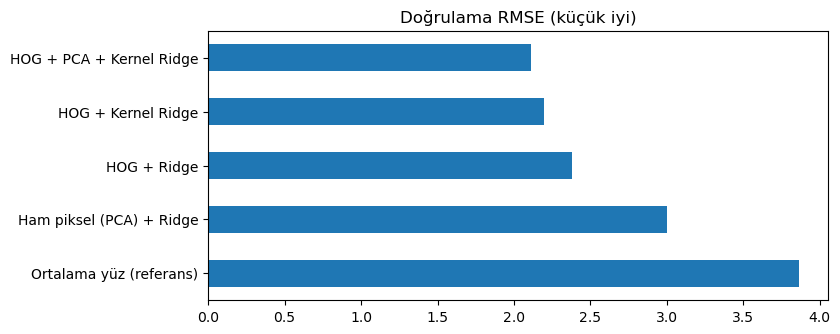

In [15]:
tablo.iloc[::-1].plot(kind='barh', legend=False, figsize=(8, 3.5))
plt.title('Doğrulama RMSE (küçük iyi)')

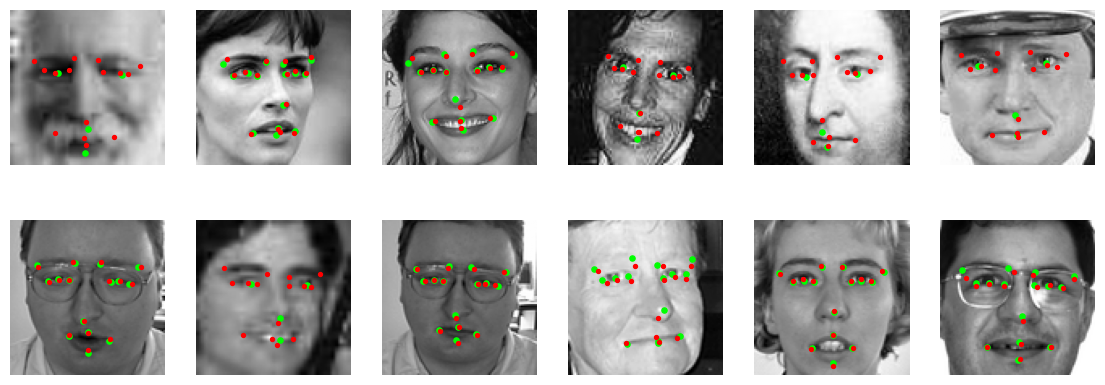

In [16]:
fig, eksenler = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(eksenler.ravel(), range(12)):
    g = X[dogrulama_idx[i]].reshape(96, 96)
    ax.imshow(g, cmap='gray')
    ax.scatter(Y_d[i, ::2], Y_d[i, 1::2], c='lime', s=14)                          
    ax.scatter(tahmin_dogrulama[i, ::2], tahmin_dogrulama[i, 1::2], c='red', s=8)   
    ax.axis('off')

In [17]:
pca_son = PCA(n_components=150, random_state=0).fit(H)
Z_tum = pca_son.transform(H).astype(np.float32)
Z_test = pca_son.transform(H_test).astype(np.float32)

gamma_son = 0.5 / (Z_tum.shape[1] * Z_tum.var())
modeller, ortalamalar = egit(lambda: KernelRidge(alpha=0.1, kernel='rbf', gamma=gamma_son), Z_tum, Y)
tahmin_test = np.clip(tahmin_et(modeller, ortalamalar, Z_test), 0, 96)      # koordinatlar 0-96 arasında olmalı
print('test tahmini:', tahmin_test.shape)

test tahmini: (1783, 30)


In [18]:
tahmin_tablo = pd.DataFrame(tahmin_test, columns=sutunlar)
tahmin_tablo.insert(0, 'ImageId', test.ImageId.values)
uzun = tahmin_tablo.melt(id_vars='ImageId', var_name='FeatureName', value_name='Location')

sonuc = lookup[['RowId', 'ImageId', 'FeatureName']].merge(uzun, on=['ImageId', 'FeatureName'], how='left')[['RowId', 'Location']]
sonuc.to_csv('sonuc1.csv', index=False)
print(sonuc.shape)
sonuc.head()

(27124, 2)


,RowId,Location
0,1,65.894742
1,2,38.345885
2,3,29.774533
3,4,36.467226
4,5,59.516898


In [19]:
print('sütunlar sample ile aynı mı:', list(sonuc.columns) == list(sample.columns))
print('satır sayısı aynı mı      :', len(sonuc) == len(sample))
print('RowId\'ler aynı mı        :', (sonuc.RowId.values == sample.RowId.values).all())
print('boş değer var mı          :', sonuc.Location.isna().any())
print('değer aralığı             :', round(sonuc.Location.min(), 1), '-', round(sonuc.Location.max(), 1))

sütunlar sample ile aynı mı: True
satır sayısı aynı mı      : True
RowId'ler aynı mı        : True
boş değer var mı          : False
değer aralığı             : 6.4 - 94.7


In [20]:
with open('model.pkl', 'wb') as f:
    pickle.dump({'pca': pca_son, 'modeller': modeller, 'ortalamalar': ortalamalar}, f)
print('model.pkl kaydedildi')

model.pkl kaydedildi


- Bu problemde girdi bir görüntü, çıktı 30 koordinat; yani **görüntüden regresyon**. Metrik RMSE olduğu için hata piksel cinsinden okunuyor.
- Verideki en önemli sorun **eksik etiketlerdi**: 11 noktanın etiketi sadece yaklaşık 2.200 görüntüde var. Eksikleri doldurmak yerine her nokta için ayrı model kurup sadece etiketi olan görüntülerle eğittik.